# 07 — Why expiry changes the market

**Question:** What changes as the BTC five-minute window runs out of time?

**By the end:** align observations by seconds remaining, compare liquidity and
quote movement across phases, and separate an observed opening-price proxy from
the official price to beat. **Time:** 30–40 minutes.

**Inputs:** both reconstructed outcome books, BTC trades, and window metadata.
This is one recorded market, not an estimate of the average expiry pattern.

In [1]:
import sys
from pathlib import Path

for directory in (Path.cwd(), *Path.cwd().parents):
    if (directory / "src/tyrex_pm").exists():
        sys.path.insert(0, str(directory / "src"))
        break

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from tyrex_pm.research.tuto_btc5m.analysis import (
    BookStudy,
    btc_grid,
    finish_plot,
    plot_style,
)
from tyrex_pm.research.tuto_btc5m.data import Sample

SAMPLE_PATH = None  # Or Path("/absolute/path/to/your/prepared_sample")
sample = Sample.open(SAMPLE_PATH)
plot_style()
pd.set_option("display.max_columns", 12)
display(pd.Series(sample.describe(), name="Pinned input"))

collection                             2dd3d0d125dc4a9fb5e50daf3f9bfd3e
market                polymarket:condition:0x540c56b66edcf6f1273c7d7...
start_utc                                     2026-10-01 15:45:00+00:00
end_utc                                       2026-10-01 15:50:00+00:00
manifest_sha256       f5a2aa939c7d60a1f48d1f6df5c0110a61dc11a7794458...
integrity_scope       selected_normalized_parts_and_sample_only_not_...
semantic_readiness                                          UNSUPPORTED
Name: Pinned input, dtype: object

## 1. Replace calendar time with the expiry clock

Two markets occur at different times but share a countdown from 300 to zero.
This clock lets us compare future collections without confusing market age with
the time of day. It does not make different market regimes identical.
The scheduled deadline is also different from the time a provider publishes a
qualified terminal result.

,time,label,seconds_left,mid,analysis_eligible
0,2026-10-01 15:45:00+00:00,Up,300.0,0.645,True
1,2026-10-01 15:45:01+00:00,Up,299.0,0.615,True
2,2026-10-01 15:45:02+00:00,Up,298.0,0.615,True
3,2026-10-01 15:45:03+00:00,Up,297.0,0.665,True
4,2026-10-01 15:45:04+00:00,Up,296.0,0.665,True
5,2026-10-01 15:45:05+00:00,Up,295.0,0.665,True
6,2026-10-01 15:45:06+00:00,Up,294.0,0.665,True
7,2026-10-01 15:45:07+00:00,Up,293.0,0.655,True


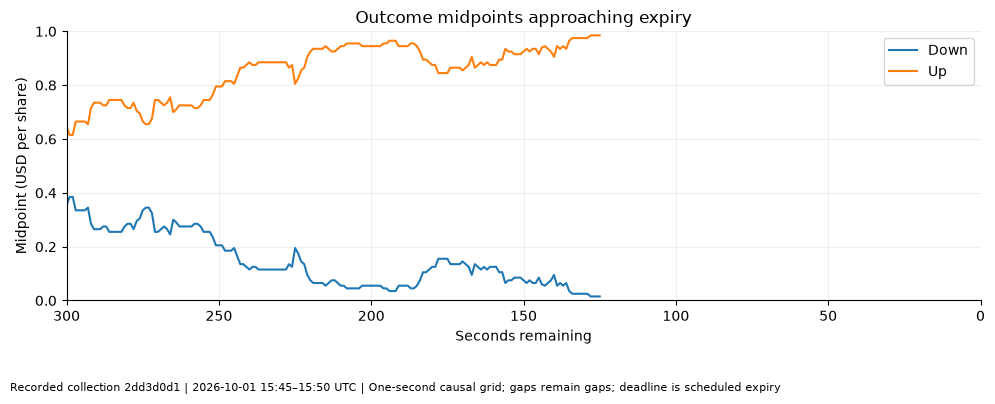

In [2]:
study = BookStudy(sample)
grid = study.grid()
grid["seconds_left"] = (pd.Timestamp(sample.end, tz="UTC") - grid.time).dt.total_seconds()
display(grid[["time", "label", "seconds_left", "mid", "analysis_eligible"]].head(8))
fig, ax = plt.subplots()
for label, frame in grid.groupby("label"):
    ax.plot(frame.seconds_left, frame.mid, label=label)
ax.set(
    title="Outcome midpoints approaching expiry",
    xlabel="Seconds remaining",
    ylabel="Midpoint (USD per share)",
    xlim=(300, 0),
    ylim=(0, 1),
)
ax.legend()
finish_plot(fig, sample, "One-second causal grid; gaps remain gaps; deadline is scheduled expiry")

## 2. A disappearing two-sided book is itself information

Near a decisive outcome, one side of a token book may become empty. That is not
necessarily a failed capture. Our midpoint analysis requires both sides, so an
empty side removes that observation from the midpoint chart.

Always show the denominator: a median spread based on ten clean observations
does not describe all sixty seconds of the last minute.

grid_points  usable_points  median_spread_USD  \
label phase                                                               
Down  Final minute                 60              0                NaN   
      Middle two minutes          120             56               0.01   
      First two minutes           120            120               0.01   
Up    Final minute                 60              0                NaN   
      Middle two minutes          120             56               0.01   
      First two minutes           120            120               0.01   

                          median_bid_shares  median_ask_shares  \
label phase                                                      
Down  Final minute                      NaN                NaN   
      Middle two minutes            541.915            580.695   
      First two minutes             587.545            403.970   
Up    Final minute                      NaN                NaN   
      Middle two minutes            580.695            541.915   
      First two minutes             403.970            587.545   

                          usable_fraction  
label phase                                
Down  Final minute               0.000000  
      Middle two minutes         0.466667  
      First two minutes          1.000000  
Up    Final minute               0.000000  
      Middle two minutes         0.466667  
      First two minutes          1.000000

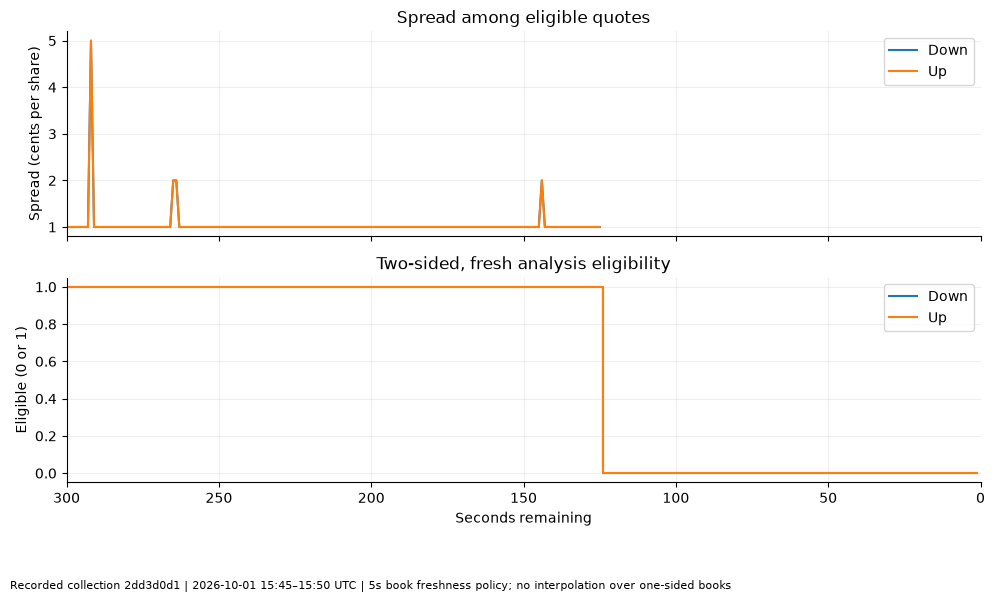

In [5]:
grid["phase"] = pd.cut(
    grid.seconds_left,
    [0, 60, 180, 301],
    labels=["Final minute", "Middle two minutes", "First two minutes"],
)
phase_report = grid.groupby(["label", "phase"], observed=True).agg(
    grid_points=("time", "size"),
    usable_points=("analysis_eligible", "sum"),
    median_spread_USD=("spread", "median"),
    median_bid_shares=("bid_quantity", "median"),
    median_ask_shares=("ask_quantity", "median"),
)
phase_report["usable_fraction"] = phase_report.usable_points / phase_report.grid_points
display(phase_report)
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for label, frame in grid.groupby("label"):
    axes[0].plot(frame.seconds_left, frame.spread * 100, label=label)
    axes[1].step(frame.seconds_left, frame.analysis_eligible.astype(int), where="post", label=label)
axes[0].set(title="Spread among eligible quotes", ylabel="Spread (cents per share)")
axes[1].set(
    title="Two-sided, fresh analysis eligibility",
    xlabel="Seconds remaining",
    ylabel="Eligible (0 or 1)",
    xlim=(300, 0),
)
for ax in axes:
    ax.legend()
finish_plot(fig, sample, "5s book freshness policy; no interpolation over one-sided books")

## 3. BTC movement relative to an explicitly labeled proxy

We use the first eligible Binance grid price as a visual anchor. It can arrive
after the exact opening boundary. It is BTC/USDT, and is **not the official
threshold**. Distance from this proxy is a descriptive relative move, not a
settlement moneyness measure.

Proxy anchor: 83889.44 USDT/BTC, first available at 2026-10-01 15:45:01+00:00
Official threshold: not inferred. Semantic readiness: UNSUPPORTED


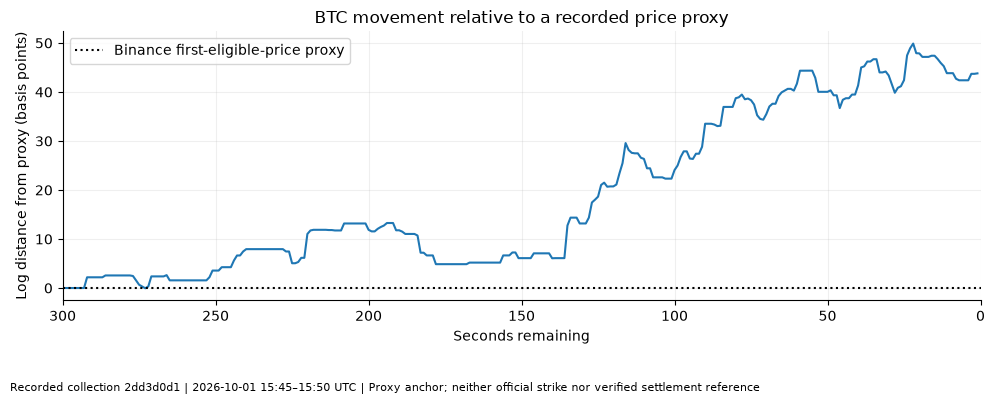

In [6]:
btc = btc_grid(sample)
first_price = btc[btc.eligible].iloc[0]
anchor, anchor_at = first_price.price_float, first_price.time
btc["proxy_distance_bps"] = np.log(btc.price_float / anchor) * 10000
btc.loc[btc.time < anchor_at, "proxy_distance_bps"] = np.nan
print("Proxy anchor:", anchor, "USDT/BTC, first available at", anchor_at)
print(
    "Official threshold: not inferred. Semantic readiness:",
    sample.quality.get("semantic_readiness", "NOT_REPORTED"),
)
fig, ax = plt.subplots()
ax.plot((pd.Timestamp(sample.end, tz="UTC") - btc.time).dt.total_seconds(), btc.proxy_distance_bps)
ax.axhline(0, color="black", linestyle=":", label="Binance first-eligible-price proxy")
ax.set(
    title="BTC movement relative to a recorded price proxy",
    xlabel="Seconds remaining",
    ylabel="Log distance from proxy (basis points)",
    xlim=(300, 0),
)
ax.legend()
finish_plot(fig, sample, "Proxy anchor; neither official strike nor verified settlement reference")

## 4. Quote movement can accelerate, but test it rather than assuming it

For Up we inspect the absolute one-second midpoint change. We only compare
consecutive eligible observations on the same session/socket. Fresh full snapshots
may supply a new price; a reconnect is not a valid price-change comparison.

The missing late observations limit what we can conclude about this window's
final seconds. Do not replace those observations with a payout of 0 or 1.

,count,median,max
phase,,,
Final minute,0,NaN,NaN
Middle two minutes,56,1.0,4.0
First two minutes,119,1.0,7.0


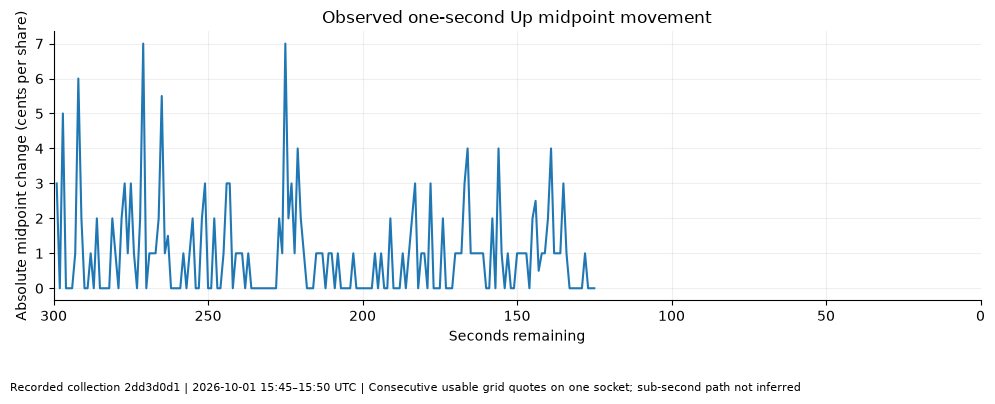

In [7]:
up = grid[grid.label.str.lower() == "up"].copy()
same_socket = (up.session_id == up.session_id.shift()) & (
    up.connection_id == up.connection_id.shift()
)
up["absolute_mid_change_cents"] = (up.mid.diff().abs() * 100).where(same_socket)
display(
    up.groupby("phase", observed=True).absolute_mid_change_cents.agg(["count", "median", "max"])
)
fig, ax = plt.subplots()
ax.plot(up.seconds_left, up.absolute_mid_change_cents)
ax.set(
    title="Observed one-second Up midpoint movement",
    xlabel="Seconds remaining",
    ylabel="Absolute midpoint change (cents per share)",
    xlim=(300, 0),
)
finish_plot(
    fig, sample, "Consecutive usable grid quotes on one socket; sub-second path not inferred"
)

## 5. Extending from one story to many windows

This optional cell accepts additional prepared samples. Selection should follow a
predeclared date range and quality policy, not attractive-looking outcomes. The
same sample must not be counted twice. With enough windows, examine distributions
and uncertainty across windows, instead of treating every update as independent.

In [8]:
ADDITIONAL_SAMPLE_PATHS = []  # e.g. [Path("/absolute/path/to/another/prepared_sample")]
stories = [grid.assign(market_id=sample.manifest["market_id"])]
seen = {sample.manifest["market_id"]}
for path in ADDITIONAL_SAMPLE_PATHS:
    other = Sample.open(path)
    if other.manifest["market_id"] in seen:
        raise ValueError("Duplicate market sample")
    seen.add(other.manifest["market_id"])
    other_grid = BookStudy(other).grid()
    other_grid["seconds_left"] = (
        pd.Timestamp(other.end, tz="UTC") - other_grid.time
    ).dt.total_seconds()
    stories.append(other_grid.assign(market_id=other.manifest["market_id"]))
display(
    pd.Series(
        {
            "independent_market_windows": len(seen),
            "interpretation": "one-window illustration"
            if len(seen) == 1
            else "multiple windows; still descriptive until representative",
        }
    )
)

independent_market_windows                          1
interpretation                one-window illustration
dtype: object

## Exercise — read the final minute honestly

Describe three things the figures establish and two they cannot establish. Is an
empty book a proof that a token paid zero?

**Suggested answer:** we observe quote paths, displayed spreads and eligibility
on this recording. We cannot establish a universal expiry law, official moneyness
from our proxy, or a settlement result from a one-sided book. A quiet, empty or
unusable price interval remains separate from a qualified payout.

**Research use:** time remaining and liquidity eligibility can be causal features.
**Next:** [08 — Cross-feed alignment](08_cross_feed_alignment.ipynb).